# Step 5. Training data to fine-tune the page reader

**The question.** Step 4 chose Qwen3-VL-2B reading whole pages, but on answer sheets it finds only 43% of the
question numbers. It has never been trained on exam pages. Can it be fine-tuned on exam-like handwriting? That
needs pages with transcriptions that are **not** from the Mendeley exams (the final evaluation) and **not** from
the development set (which will judge the fine-tuned reader against the pretrained one in step 6).

No public dataset has whole exam pages with transcriptions, so the set is put together from three sources:

| Source | What it is | Licence | Used for |
|---|---|---|---|
| GNHK (Lee, Chung and Lee, ICDAR 2021) | 687 phone photos of real English handwriting from four continents: notes, diaries, lists; every word boxed and transcribed | CC BY 4.0 | real pages, many writers |
| OpenHand-Synth (`to-be/OpenHand-Synth`) | single lines of synthetic handwriting in many hands | CC BY 4.0 | the answer text on synthetic exam pages |
| EMNIST balanced (Cohen et al. 2017) | handwritten digits and letters, 28 x 28 | CC BY 4.0 (Hugging Face copy) | question numbers and A-D letters |

Each example is a page image and the text the reader should write for it, in the format the reader is asked
for (`reader.VLM_PAGE_PROMPT`): one line of text per handwritten line, top to bottom, question numbers kept.

    Part 1  GNHK                 explore, clean (rotation, unreadable words, printed words), and check for leaks
    Part 2  OpenHand and EMNIST  explore and clean the pieces the synthetic pages are made of
    Part 3  Synthetic exams      answer pages: '7. B', '8) answer text', '2a) ...' on white or ruled paper
    Part 4  The training set     save it, describe it, and check nothing in it is in the development set

Run with `uv run --group train python -m vision.step5_finetune_data` after downloading the data (vision/README.md).
It writes `~/.cache/daiist-vision/finetune/built/{train,val}.jsonl` with their images.

In [1]:
import gzip
import hashlib
import io
import json
import random
import re
import sys
import zlib
from collections import defaultdict
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vision" / "reader.py").is_file())
sys.path.insert(0, str(ROOT))

import cv2  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import pyarrow as pa  # noqa: E402
import pyarrow.parquet as pq  # noqa: E402
from PIL import Image, ImageOps  # noqa: E402

from vision import datasets, devset, eda, reader  # noqa: E402

pd.set_option("display.width", 140)
OUT = datasets.ARTIFACTS / "step5_finetune_data"
FINETUNE = datasets.WORK / "finetune"
GNHK = FINETUNE / "gnhk"          # radhakrishnadeshpande/gnhk-pagelevel: the original images and word annotations
OPENHAND = FINETUNE / "openhand"  # to-be/OpenHand-Synth, its validation split (6,808 images, 15 languages)
EMNIST = FINETUNE / "emnist"      # Heliosoph/EMNIST, the balanced split
BUILT = FINETUNE / "built"
SEED = 0
# Synthetic pages: half as many as GNHK pages would allow. The pretrained reader already reads them almost
# perfectly (validation loss 0.24, against 1.03 on GNHK; step 6), and each takes about 17 s to train on a laptop.
N_EXAM = {"train": 500, "val": 100}
VAL_WRITERS = 0.15  # share of OpenHand writers kept for validation pages, so no writer is in both splits
PAGE_W = reader.VLM_PAGE_WIDTH
PAGE_H = round(PAGE_W * 297 / 210)  # A4
PAINT_OUT = {"%NA%", "%math%"}  # GNHK: unreadable words and drawn symbols are not text, so they are painted out
SKIP = {"%SC%"}                 # GNHK: crossed-out words stay on the page but are not part of the answer
# EMNIST balanced: 0-9 digits, 10-35 A-Z, then the lowercase letters that differ from their capitals
EMNIST_CLASSES = list("0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ") + list("abdefghnqrt")
MCQ = "ABCD"

missing = [p for p in (GNHK, OPENHAND, EMNIST) if not any(p.glob("*"))]
if missing:
    raise SystemExit(f"Download the fine-tuning data first (see vision/README.md): {missing}")

## Part 1. GNHK: real pages

GNHK stores each page photo with the words on it: the text, a four-point polygon, the line the word belongs to,
and a type (H handwritten, P printed). The page's text is rebuilt from the words: each line's words left to
right, the lines top to bottom.

Three problems were found by looking at the pages, and are fixed here:

- **Rotated photos.** Some photos are stored on their side with a camera rotation tag (EXIF), and their word
  boxes are drawn on the upright page. The tag is applied first, or every box would be in the wrong place.
- **Words that are not text.** `%NA%` (unreadable) and `%math%` (a drawn symbol) are painted out with the page's
  background colour: the reader cannot be asked to write them. `%SC%` (crossed out) stays on the page but not in
  the text, as in the development set. Printed words stay on the page but not in the text, because the reader is
  asked for the handwriting only.
- **The same page twice.** GNHK's split is by photo, not by page: some notebook pages were photographed twice,
  once in each split (eng_AS_063 in test is eng_AS_044 in train, framed differently). Validation pages that share
  a line of 20 characters or more with a training page are dropped, and a file found twice in train is kept once.

In [2]:


def to_gray(data: bytes) -> tuple[np.ndarray, bool]:
    """The photo, upright and in grey levels, and whether it carried a rotation tag."""
    image = Image.open(io.BytesIO(data))
    rotated = image.getexif().get(274, 1) != 1  # 274 is the EXIF orientation tag; 1 means already upright
    return np.array(ImageOps.exif_transpose(image).convert("L")), rotated


def fit_width(page: np.ndarray) -> np.ndarray:
    """Shrink to the width the reader sees pages at (never enlarge)."""
    scale = min(1.0, PAGE_W / page.shape[1])
    return cv2.resize(page, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)


def gnhk_page(image: np.ndarray, annotations: list[dict]) -> tuple[np.ndarray, str, dict]:
    """The page with unreadable words and symbols painted out, its handwritten text, and what was in it."""
    image = image.copy()
    background = int(np.median(image))
    lines = defaultdict(list)
    counts = defaultdict(int)
    for word in annotations:
        xy = np.array([[word["polygon"][f"x{i}"], word["polygon"][f"y{i}"]] for i in range(4)], np.int32)
        counts[word["text"] if word["text"] in PAINT_OUT | SKIP else ("printed" if word["type"] == "P" else "handwritten")] += 1
        if word["text"] in PAINT_OUT:
            cv2.fillPoly(image, [xy], background)
        elif word["type"] == "H" and word["text"] not in SKIP:
            lines[word["line_idx"]].append((xy[:, 0].mean(), xy[:, 1].mean(), word["text"]))
    rows = sorted((np.mean([w[1] for w in words]), " ".join(w[2] for w in sorted(words)))
                  for words in lines.values())
    return image, "\n".join(text for _, text in rows), dict(counts)


def gnhk_pages(split: str) -> list[dict]:
    out = []
    for path in sorted(GNHK.glob(f"{split}-*.parquet")):
        for row in pq.read_table(path, columns=["image", "filename", "annotations"]).to_pylist():
            gray, rotated = to_gray(row["image"]["bytes"])
            image, text, counts = gnhk_page(gray, json.loads(row["annotations"]))
            if text:
                out.append({"kind": "gnhk", "source": row["filename"], "image": fit_width(image), "text": text,
                            "md5": hashlib.md5(row["image"]["bytes"]).hexdigest(), "rotated": rotated,
                            "photo_width": gray.shape[1], "photo_height": gray.shape[0], **counts})
    return out


def text_lines(text: str) -> set[str]:
    """The page's lines of 20 characters or more, compared without case and punctuation."""
    return {norm for line in text.splitlines() if len(norm := re.sub(r"\W+", " ", line.lower()).strip()) >= 20}


def drop_leaks(train: list[dict], val: list[dict]) -> tuple[list[dict], list[dict], list[str]]:
    """Keep one copy of each training file (same bytes), and drop validation pages that share a line with train."""
    seen, kept = set(), []
    for page in train:
        if page["md5"] not in seen:
            seen.add(page["md5"])
            kept.append(page)
    lines = set().union(*(text_lines(p["text"]) for p in kept))
    clean = [p for p in val if not text_lines(p["text"]) & lines]
    dropped = [p["source"] for p in val if text_lines(p["text"]) & lines]
    return kept, clean, dropped


GNHK: rotated photos and words of each kind, per split:


,rotated,handwritten,printed,%NA%,%math%,%SC%
split,,,,,,
test,55,8830,829,150,126,131
train,141,28578,2633,316,528,440



GNHK, per page:


,lines,numbered_lines,photo_width,photo_height
count,687.000,687.000,687.000,687.000
missing,0.000,0.000,0.000,0.000
min,2.000,0.000,486.000,140.000
median,10.000,0.000,2849.000,2343.000
mean,13.183,0.435,2493.908,2441.849
max,110.000,20.000,4608.000,5847.000


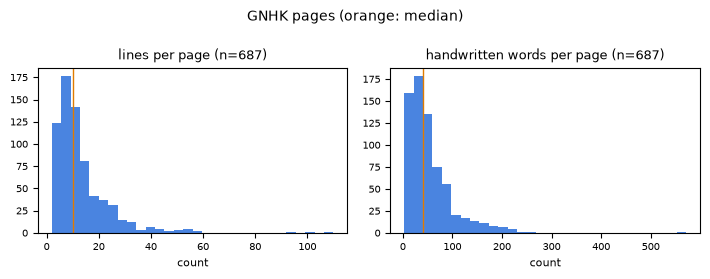

figure: eda_gnhk.png


In [3]:
train, val = gnhk_pages("train"), gnhk_pages("test")
gnhk_table = pd.DataFrame([{k: v for k, v in p.items() if k != "image"} | {"split": s}
                           for s, pages in (("train", train), ("test", val)) for p in pages]).fillna(0)
gnhk_table["lines"] = gnhk_table["text"].str.count("\n") + 1
gnhk_table["numbered_lines"] = gnhk_table["text"].map(lambda t: sum(bool(reader.LEADING_NUMBER.match(l)) for l in t.splitlines()))
word_columns = [c for c in ("handwritten", "printed", "%NA%", "%math%", "%SC%") if c in gnhk_table]
eda.show(gnhk_table.groupby("split")[["rotated"] + word_columns].sum().astype(int),
         "GNHK: rotated photos and words of each kind, per split:")
eda.show(pd.DataFrame({c: eda.describe(gnhk_table[c]) for c in ("lines", "numbered_lines", "photo_width", "photo_height")}),
         "GNHK, per page:")
eda.histograms({"lines per page": gnhk_table["lines"], "handwritten words per page": gnhk_table["handwritten"]},
               "count", OUT / "eda_gnhk.png", "GNHK pages (orange: median)")

In [4]:
kept, clean, dropped = drop_leaks(train, val)
print(f"train {len(train)} pages, {len(train) - len(kept)} duplicate files dropped -> {len(kept)}")
print(f"validation {len(val)} pages, {len(dropped)} share text with a training page and are dropped -> {len(clean)}")
print("dropped:", dropped)
gnhk = {"train": kept, "val": clean}

train 515 pages, 3 duplicate files dropped -> 512
validation 172 pages, 11 share text with a training page and are dropped -> 161
dropped: ['eng_AF_041.jpg', 'eng_AS_036.jpg', 'eng_AS_045.jpg', 'eng_AS_063.jpg', 'eng_EU_014.jpg', 'eng_EU_069.jpg', 'eng_EU_139.jpg', 'eng_EU_313.jpg', 'eng_NA_065.jpg', 'eng_NA_085.jpg', 'eng_NA_142.jpg']


**What GNHK brings.** Real photos of real handwriting, with shadows, ruling and many writers, but few question
numbers: only a handful of its lines open with a number. The exam layout has to come from synthetic pages.

## Part 2. OpenHand and EMNIST: the pieces of a synthetic exam page

**OpenHand-Synth** gives lines of handwriting with their text, in 15 languages and from several text sources.
Only single English lines from Simple Wikipedia and Tatoeba (everyday sentences) are kept: other languages would
teach the reader to expect them, and multi-line entries do not fit a line on the page. Some lines were scanned
on a grey background that would show as a grey box on a white page: their background (90th percentile) is
brought to white. Lines are split by **writer**, 15% of writers to validation, so no hand is in both splits.

**EMNIST** gives single handwritten characters for the question numbers and the A-D answers. The files store
each 28 x 28 character transposed and as light ink on black, so each is transposed, inverted and cropped to its
ink. EMNIST's own train and test files go to our train and validation pages.

In [5]:


def white_background(ink: np.ndarray) -> np.ndarray:
    """Bring the background (the 90th percentile) to white and scale the ink with it."""
    return np.clip(ink.astype(np.float32) * 255 / max(np.percentile(ink, 90), 1), 0, 255).astype(np.uint8)


rows = []
for path in sorted(OPENHAND.glob("data-*.arrow")):
    with pa.ipc.open_stream(path) as stream:
        rows += stream.read_all().select(["image", "text", "writer_id", "language", "source"]).to_pylist()
openhand_table = pd.DataFrame([{k: r[k] for k in ("writer_id", "language", "source")} | {"multi_line": "\\n" in r["text"]}
                               for r in rows])
eda.show(openhand_table["language"].value_counts().head(8), "OpenHand lines per language (top 8):")
eda.show(openhand_table[openhand_table["language"] == "eng"]["source"].value_counts(), "English lines per text source:")

lines = {"train": [], "val": []}
grey, writers = 0, {"train": set(), "val": set()}
for r in rows:
    if r["language"] == "eng" and r["source"] in ("wikipedia-simple", "tatoeba") and "\\n" not in r["text"]:
        gray, _ = to_gray(r["image"]["bytes"])
        grey += np.percentile(gray, 90) < 245
        split = "val" if zlib.crc32(str(r["writer_id"]).encode()) % 100 < VAL_WRITERS * 100 else "train"
        lines[split].append((white_background(gray), r["text"].strip()))
        writers[split].add(r["writer_id"])
kept_lines = pd.Series({s: len(v) for s, v in lines.items()})
eda.show(pd.DataFrame({"lines": kept_lines, "writers": pd.Series({s: len(w) for s, w in writers.items()})}),
         "OpenHand lines kept, per split:")
print(f"lines on a grey background, whitened: {grey}")
print(f"writers in both splits: {len(writers['train'] & writers['val'])} (must be 0)")
shared = {t for _, t in lines["train"]} & {t for _, t in lines["val"]}
print(f"sentences in both splits (written by different writers): {len(shared)}")


OpenHand lines per language (top 8):


language
eng    3302
por     240
fra     236
nld     230
deu     229
spa     217
swe     211
nob     210
Name: count, dtype: int64


English lines per text source:


source
wikipedia-simple     2985
tatoeba               100
faker-name             97
tatoeba-multiline      73
faker-date             47
Name: count, dtype: int64


OpenHand lines kept, per split:


,lines,writers
train,1813,188
val,319,32


lines on a grey background, whitened: 170
writers in both splits: 0 (must be 0)
sentences in both splits (written by different writers): 4



EMNIST characters available per split:


,a,4,1,D,C,5,3,9,b,7,2,8,A,6,B,0
train,2400,2400,2400,2400,2400,2400,2400,2400,2400,2400,2400,2400,2400,2400,2400,2400
val,400,400,400,400,400,400,400,400,400,400,400,400,400,400,400,400


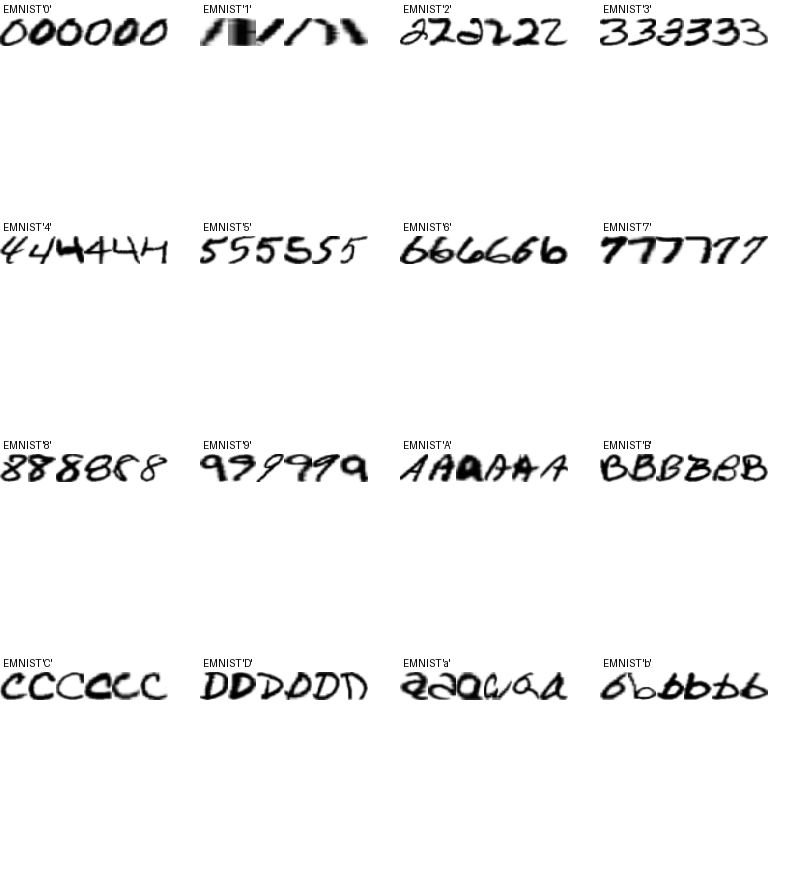

image: eda_emnist.png


In [6]:


def emnist_glyphs(split: str) -> dict[str, list[np.ndarray]]:
    """EMNIST digits, A-D and a-b as dark ink on white, cropped to the ink."""
    def idx(name: str, offset: int) -> np.ndarray:
        return np.frombuffer(gzip.open(EMNIST / f"emnist-balanced-{split}-{name}.gz").read()[offset:], np.uint8)
    images = idx("images-idx3-ubyte", 16).reshape(-1, 28, 28).transpose(0, 2, 1)
    labels = idx("labels-idx1-ubyte", 8)
    glyphs = defaultdict(list)
    for image, label in zip(images, labels):
        char = EMNIST_CLASSES[label]
        if char.isdigit() or char in MCQ or char in "ab":
            ys, xs = np.nonzero(image > 40)
            glyphs[char].append(255 - image[ys.min():ys.max() + 1, xs.min():xs.max() + 1])
    return glyphs


glyphs = {"train": emnist_glyphs("train"), "val": emnist_glyphs("test")}
eda.show(pd.DataFrame({s: {c: len(v) for c, v in g.items()} for s, g in glyphs.items()}).T,
         "EMNIST characters available per split:")
eda.contact_sheet([np.hstack([cv2.resize(glyphs["train"][c][k], (28, 28)) for k in range(6)]) for c in "0123456789ABCDab"],
                  [f"EMNIST '{c}'" for c in "0123456789ABCDab"], OUT / "eda_emnist.png", thumb=200)

One limit is visible in the contact sheet: EMNIST characters are 28 pixels, so once enlarged to a question
number they look thicker and blurrier than pen writing, and a few are ambiguous (an EMNIST '8' can look like
'P'). The synthetic pages will be easier to read than real ones.

## Part 3. Synthetic exam pages

An A4 answer page, white or ruled. Questions are numbered from a random start with EMNIST digits and a pen-drawn
"." or ")", and about 15% of written answers get a sub-part ("2a)"). Each question is answered with an EMNIST
letter A to D (40%) or with one to three OpenHand lines (60%), written down the page until it is full. The
target text follows the reader's prompt: one line per written line, numbers kept at the start.

In [7]:


def paste(page: np.ndarray, ink: np.ndarray, x: int, y: int) -> int:
    """Darken the page with this ink at (x, y), clipped to the page; returns the x after it."""
    y0, x0 = max(y, 0), max(x, 0)
    h, w = min(ink.shape[0] - (y0 - y), page.shape[0] - y0), min(ink.shape[1] - (x0 - x), page.shape[1] - x0)
    if h > 0 and w > 0:
        page[y0:y0 + h, x0:x0 + w] = np.minimum(page[y0:y0 + h, x0:x0 + w], ink[y0 - y:y0 - y + h, x0 - x:x0 - x + w])
    return x + ink.shape[1]


def scaled(ink: np.ndarray, height: int) -> np.ndarray:
    return cv2.resize(ink, (max(1, round(ink.shape[1] * height / ink.shape[0])), height), interpolation=cv2.INTER_AREA)


def write_label(page: np.ndarray, label: str, sep: str, glyphs: dict, x: int, y: int, height: int,
                rng: random.Random) -> int:
    """A question number ('12', '2a') from EMNIST characters, then its separator drawn as a pen mark."""
    for char in label:
        ink = scaled(rng.choice(glyphs[char]), height if char.isdigit() else round(height * 0.75))
        x = paste(page, ink, x, y + height - ink.shape[0]) + rng.randint(1, 5)
    thickness = max(2, height // 12)
    if sep == ".":
        cv2.circle(page, (x + thickness, y + height - thickness), thickness, 30, -1)
        return x + 3 * thickness
    cv2.ellipse(page, (x, y + height // 2), (height // 4, height // 2), 0, -70, 70, 30, thickness)
    return x + height // 4 + thickness


def exam_page(lines: list, glyphs: dict, rng: random.Random) -> tuple[np.ndarray, str]:
    """An exam answer page and its text."""
    page = np.full((PAGE_H, PAGE_W), 255, np.uint8)
    ruled = rng.random() < 0.5
    pitch = rng.randint(60, 80)  # distance between written rows
    if ruled:
        page[np.arange(150, PAGE_H - 60, pitch)] = 205
    height = round(pitch * rng.uniform(0.45, 0.6))  # height of a number; answer lines are drawn a little taller
    number = rng.randint(1, 40)
    sep = rng.choice(".)")
    margin = rng.randint(50, 110)
    y = 150 - round(pitch * 0.8) if ruled else rng.randint(80, 160)
    text = []
    while True:
        written = rng.random() < 0.6
        n_rows = rng.randint(1, 3) if written else 1
        if y + n_rows * pitch > PAGE_H - 80:
            break
        part = rng.choice("ab") if written and rng.random() < 0.15 else ""
        label = f"{number}{part}"
        mark = ")" if part else sep
        x = write_label(page, label, mark, glyphs, margin, y, height, rng) + rng.randint(15, 35)
        if written:
            rows_ = []
            for k in range(n_rows):
                ink, line_text = rng.choice(lines)
                ink = scaled(ink, round(height * 1.5))
                left = x if k == 0 else margin + rng.randint(0, 40)
                if ink.shape[1] > PAGE_W - left - 40:  # squeeze a long line into the page
                    ink = cv2.resize(ink, (PAGE_W - left - 40, ink.shape[0]), interpolation=cv2.INTER_AREA)
                paste(page, ink, left, y + k * pitch - round(height * 0.3))
                rows_.append(line_text)
            text.append(f"{label}{mark} " + "\n".join(rows_))
        else:
            letter = rng.choice(MCQ)
            paste(page, scaled(rng.choice(glyphs[letter]), height), x, y)
            text.append(f"{label}{mark} {letter}")
        y += n_rows * pitch + (0 if ruled else rng.randint(0, pitch // 2))
        number += 1
    noise = np.random.default_rng(rng.randint(0, 2**31))  # light scanner noise
    page = np.clip(page.astype(int) - noise.integers(0, 10, page.shape), 0, 255).astype(np.uint8)
    return page, "\n".join(text)


def exam_pages(split: str, lines: list, glyphs: dict) -> list[dict]:
    rng = random.Random(f"{SEED}-{split}")
    out = []
    for k in range(N_EXAM[split]):
        image, text = exam_page(lines, glyphs, rng)
        out.append({"kind": "exam", "source": f"synthetic_{split}_{k:04d}", "image": image, "text": text})
    return out

--- the text of the first training page ---
25) Money (Pink Floyd song)
26) United States District Court for the Northern District of New York
Virtual Boy Wario Land
27) Guria is divided into 3 municipalities:
Vilivalla, Hiiu County
28) B
29) National Collegiate Athletic Association
30) -Knight of the Order of the Gold Lion of the House of Nassau
Mountbatten MRT station
He earned 18 caps in the Argentina national team between 1962 and 1966.
31) Richard Bertrand Spencer (born May 11, 1978) is an American white supremacist.
In 2007, 10625 people lived there.
32) Farber is a city in Audrain County, Missouri, United States.
Marie-Claire Kirkland
33) Penal Code 1994, Article 268 Lesbianism
I won't wait past 2:30.
Nemai Ghosh (photographer)
34a) The House on Trubnaya
Scandinavian Airlines
35) C
36) C
37) C


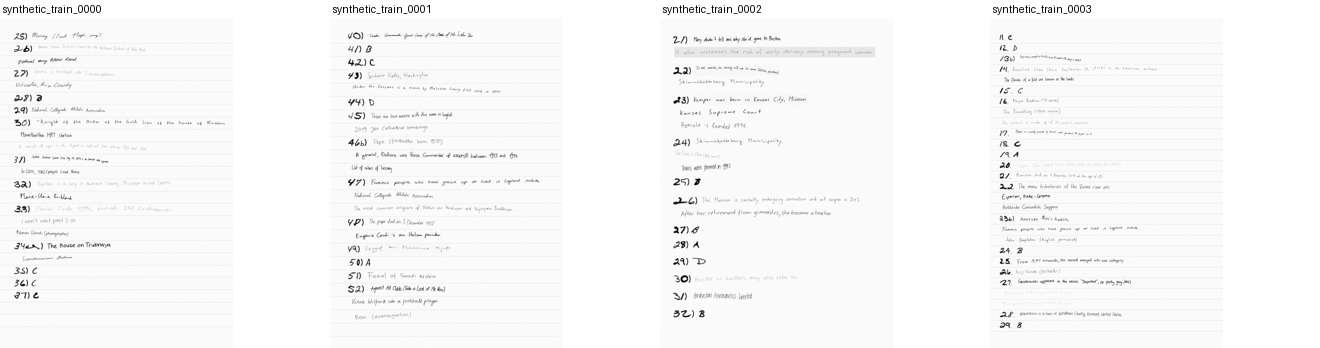

image: eda_exam_pages.png


In [8]:
exams = {split: exam_pages(split, lines[split], glyphs[split]) for split in ("train", "val")}
print("--- the text of the first training page ---\n" + exams["train"][0]["text"])
eda.contact_sheet([e["image"] for e in exams["train"][:4]], [e["source"] for e in exams["train"][:4]],
                  OUT / "eda_exam_pages.png", thumb=330)
for k in range(3):  # three pages with their text, to open at full size
    cv2.imwrite(str(OUT / f"exam_train_{k}.jpg"), exams["train"][k]["image"])
    (OUT / f"exam_train_{k}.txt").write_text(exams["train"][k]["text"])

## Part 4. The training set: save, describe, check

GNHK pages and synthetic pages together, saved as JPEG images with one JSON line each (image, text, kind,
source). The GNHK photos are other people's notes, so they stay in the work folder, off the repo; only synthetic
samples are kept in `artifacts/`.

In [9]:


def save(split: str, examples: list[dict]) -> pd.DataFrame:
    folder = BUILT / split
    folder.mkdir(parents=True, exist_ok=True)
    rows_ = []
    for k, ex in enumerate(examples):
        path = folder / f"{ex['kind']}_{k:04d}.jpg"
        cv2.imwrite(str(path), ex["image"], [cv2.IMWRITE_JPEG_QUALITY, 92])
        rows_.append({"image": str(path), "text": ex["text"], "kind": ex["kind"], "source": ex["source"]})
    with open(BUILT / f"{split}.jsonl", "w") as f:
        for r in rows_:
            f.write(json.dumps(r) + "\n")
    return pd.DataFrame(rows_)


built = pd.concat([save(split, gnhk[split] + exams[split]).assign(split=split) for split in ("train", "val")])
built["lines"] = built["text"].str.count("\n") + 1
built["numbered_lines"] = built["text"].map(lambda t: sum(bool(reader.LEADING_NUMBER.match(l)) for l in t.splitlines()))
built["chars"] = built["text"].str.len()


The fine-tuning set:


pages  lines  numbered_lines  median_chars
split kind                                            
train exam    500  11630            7368         791.0
      gnhk    512   6842             236         228.0
val   exam    100   2307            1464         785.5
      gnhk    161   1931              53         215.0

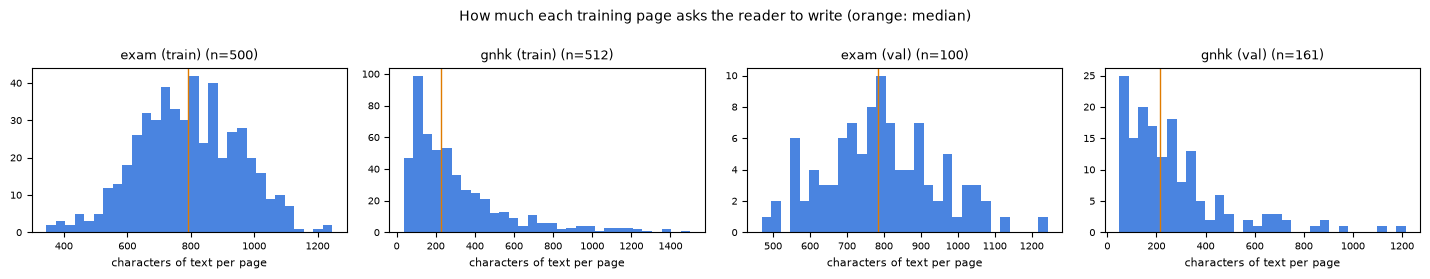

figure: eda_text_per_page.png


754

In [10]:
table = built.groupby(["split", "kind"]).agg(pages=("image", "size"), lines=("lines", "sum"),
                                             numbered_lines=("numbered_lines", "sum"), median_chars=("chars", "median"))
eda.show(table, "The fine-tuning set:")
eda.histograms({f"{k} ({s})": part["chars"] for (s, k), part in built.groupby(["split", "kind"])},
               "characters of text per page", OUT / "eda_text_per_page.png",
               "How much each training page asks the reader to write (orange: median)")
summary = {split: table.loc[split][["pages", "lines", "numbered_lines"]].to_dict(orient="index") for split in ("train", "val")}
summary["gnhk_dropped"] = {"duplicate_train_files": len(train) - len(kept), "val_pages_sharing_text": dropped}
(OUT / "finetune_data.json").write_text(json.dumps(summary, indent=2, default=int))

In [11]:
# A line of 25 characters or more that appears in both would mean step 6 judges the reader on text it was trained on.
dev = devset.build()
dev_lines = {re.sub(r"\W+", " ", l.lower()).strip() for t in dev["truth"].dropna() for l in t.splitlines()}
dev_lines = {l for l in dev_lines if len(l) >= 25}
train_lines = {re.sub(r"\W+", " ", l.lower()).strip() for t in built["text"] for l in t.splitlines()}
print(f"lines of 25+ characters shared with the development set: {len(dev_lines & train_lines)} (must be 0)")
assert not dev_lines & train_lines

lines of 25+ characters shared with the development set: 0 (must be 0)


## Conclusion, and why it leads to step 6

The fine-tuning set has 1,012 training pages (512 real GNHK photos and 500 synthetic exam pages) and 261
validation pages (161 and 100), with thousands of numbered lines on the synthetic pages, where GNHK has only a
few hundred. Rotations, unreadable words, grey backgrounds and repeated pages were fixed before anything was
trained, and no writer, page or line is shared with validation or with the development set. Step 6 trains the
page reader on it and asks the one question that matters: does it find more question numbers on the development
set's answer sheets?